# Experiment 9: Bootstrapping and Cross-Validation on the Iris Dataset
## Aim
Implement bootstrapping and k-fold cross-validation on the Iris dataset, compare the model performance metrics (accuracy, F1-score) obtained using these resampling methods, and discuss the advantages and disadvantages of each.

## Theory
A single train/test split gives only **one** estimate of model performance, and that estimate depends heavily on which samples happened to land in the test set — especially on a small dataset like Iris (150 samples). **Resampling methods** reuse the same data many times in different ways to get a more reliable estimate, and to measure how much that estimate varies.

**Bootstrapping**: repeatedly draw a sample of size *n* **with replacement** from the dataset of size *n*. Each bootstrap sample contains some rows multiple times and leaves out others — on average about **63.2%** of the unique rows appear in a bootstrap sample. The model is trained on the bootstrap sample and evaluated on the left-out rows, called the **out-of-bag (OOB)** samples (about 36.8%). Repeating this hundreds or thousands of times gives a whole *distribution* of scores, from which a mean, standard deviation, and confidence interval can be computed.

**k-Fold Cross-Validation**: split the data into *k* equal folds (here stratified, so each fold keeps the class proportions). Train on *k−1* folds and test on the remaining fold, rotating so every sample is used for testing **exactly once**. The *k* scores are averaged to give the final estimate.

**Data leakage note**: scaling must be learned from training data only. To guarantee this inside every bootstrap iteration and every fold, a `Pipeline(StandardScaler, LogisticRegression)` is used, so the scaler is re-fit on each training set separately.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

## Load and Preprocess the Iris Dataset

In [2]:
iris=load_iris()
df=pd.DataFrame(iris.data,columns=iris.feature_names)
df['species']=pd.Categorical.from_codes(iris.target,iris.target_names)
print(df.shape)
print(df.isnull().sum().sum(),'missing values')
print(df['species'].value_counts())
df.head()

(150, 5)
0 missing values
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
X=iris.data
y=iris.target

model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))

## Baseline: Single Train/Test Split
First, the same model is evaluated with a plain 80/20 hold-out split using 10 different random seeds. If one split were reliable, all ten scores would be nearly identical — the spread shows why a single split is risky.

In [4]:
holdout_acc=[]
for seed in range(10):
    X_tr,X_te,y_tr,y_te=train_test_split(X,y,test_size=0.2,random_state=seed,stratify=y)
    model.fit(X_tr,y_tr)
    holdout_acc.append(accuracy_score(y_te,model.predict(X_te)))

print('Hold-out accuracy per seed:',np.round(holdout_acc,3))
print('Min: %.3f  Max: %.3f  Mean: %.3f  Std: %.3f'%(min(holdout_acc),max(holdout_acc),np.mean(holdout_acc),np.std(holdout_acc)))

Hold-out accuracy per seed: [0.967 0.967 1.    0.867 0.967 0.967 0.933 1.    0.933 0.967]
Min: 0.867  Max: 1.000  Mean: 0.957  Std: 0.037


## Bootstrapping
For each of 1000 iterations: draw a bootstrap sample (with replacement), train on it, and evaluate on the out-of-bag rows. Accuracy and macro-averaged F1-score are recorded each time.

In [5]:
n_iterations=1000
n=len(X)
rng=np.random.RandomState(42)

boot_acc=[]
boot_f1=[]
oob_fraction=[]

t0=time.time()
for i in range(n_iterations):
    train_idx=rng.choice(n,size=n,replace=True)
    oob_idx=np.setdiff1d(np.arange(n),train_idx)
    if len(oob_idx)==0:
        continue
    model.fit(X[train_idx],y[train_idx])
    pred=model.predict(X[oob_idx])
    boot_acc.append(accuracy_score(y[oob_idx],pred))
    boot_f1.append(f1_score(y[oob_idx],pred,average='macro'))
    oob_fraction.append(len(oob_idx)/n)
boot_time=time.time()-t0

print('Bootstrap iterations     :',len(boot_acc))
print('Avg OOB fraction         : %.3f (theory: ~0.368)'%np.mean(oob_fraction))
print('Accuracy  mean +/- std   : %.4f +/- %.4f'%(np.mean(boot_acc),np.std(boot_acc)))
print('Accuracy  95%% interval   : [%.4f, %.4f]'%tuple(np.percentile(boot_acc,[2.5,97.5])))
print('F1 (macro) mean +/- std  : %.4f +/- %.4f'%(np.mean(boot_f1),np.std(boot_f1)))
print('Time taken               : %.2f s'%boot_time)

Bootstrap iterations     : 1000
Avg OOB fraction         : 0.367 (theory: ~0.368)
Accuracy  mean +/- std   : 0.9568 +/- 0.0241
Accuracy  95% interval   : [0.9091, 1.0000]
F1 (macro) mean +/- std  : 0.9560 +/- 0.0246
Time taken               : 4.80 s


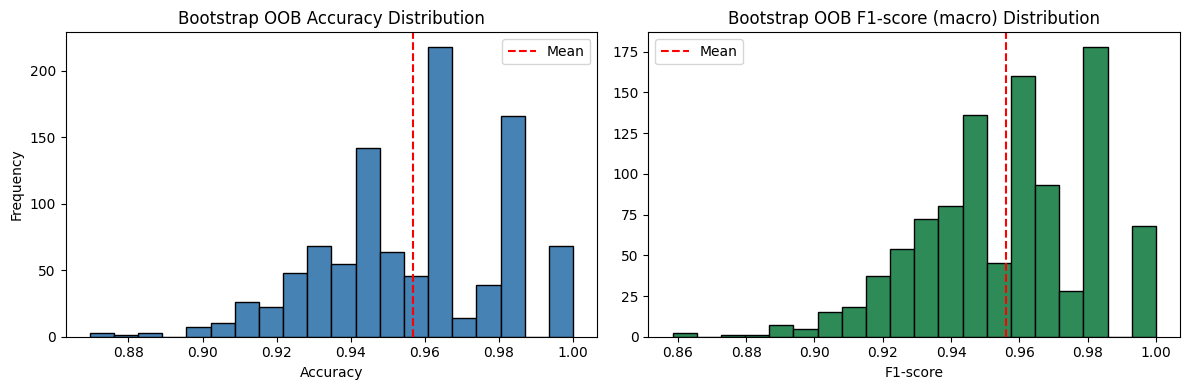

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(boot_acc,bins=20,color='steelblue',edgecolor='k')
axes[0].axvline(np.mean(boot_acc),color='red',linestyle='--',label='Mean')
axes[0].set_title('Bootstrap OOB Accuracy Distribution')
axes[0].set_xlabel('Accuracy')
axes[0].set_ylabel('Frequency')
axes[0].legend()

axes[1].hist(boot_f1,bins=20,color='seagreen',edgecolor='k')
axes[1].axvline(np.mean(boot_f1),color='red',linestyle='--',label='Mean')
axes[1].set_title('Bootstrap OOB F1-score (macro) Distribution')
axes[1].set_xlabel('F1-score')
axes[1].legend()
plt.tight_layout()
plt.show()

## k-Fold Cross-Validation
Stratified 10-fold cross-validation is used as the main setting, with 5-fold shown alongside it.

In [7]:
cv_results={}
for k in [5,10]:
    skf=StratifiedKFold(n_splits=k,shuffle=True,random_state=42)
    t0=time.time()
    res=cross_validate(model,X,y,cv=skf,scoring=['accuracy','f1_macro'])
    cv_results[k]={'acc':res['test_accuracy'],'f1':res['test_f1_macro'],'time':time.time()-t0}
    print(f'{k}-fold CV')
    print('  Accuracy per fold :',np.round(res['test_accuracy'],3))
    print('  Accuracy mean+/-std: %.4f +/- %.4f'%(res['test_accuracy'].mean(),res['test_accuracy'].std()))
    print('  F1 (macro) mean+/-std: %.4f +/- %.4f'%(res['test_f1_macro'].mean(),res['test_f1_macro'].std()))
    print('  Time: %.3f s'%cv_results[k]['time'])
    print()

5-fold CV
  Accuracy per fold : [1.    0.967 0.9   1.    0.9  ]
  Accuracy mean+/-std: 0.9533 +/- 0.0452
  F1 (macro) mean+/-std: 0.9532 +/- 0.0453
  Time: 0.030 s

10-fold CV
  Accuracy per fold : [1.    1.    1.    0.933 0.867 0.933 1.    1.    0.933 0.867]
  Accuracy mean+/-std: 0.9533 +/- 0.0521
  F1 (macro) mean+/-std: 0.9526 +/- 0.0531
  Time: 0.055 s



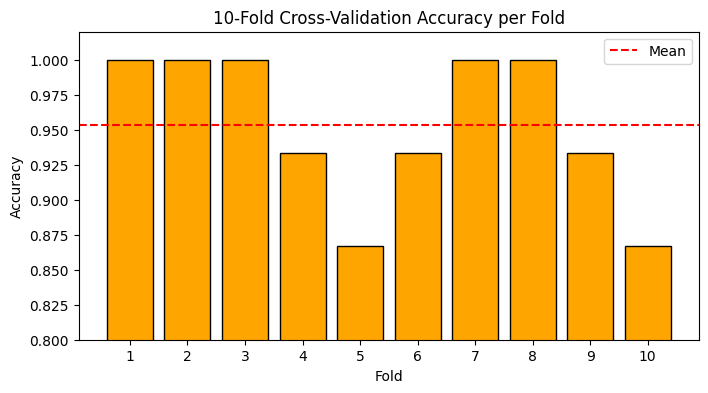

In [8]:
plt.figure(figsize=(8,4))
folds=np.arange(1,11)
plt.bar(folds,cv_results[10]['acc'],color='orange',edgecolor='k')
plt.axhline(cv_results[10]['acc'].mean(),color='red',linestyle='--',label='Mean')
plt.xticks(folds)
plt.ylim(0.8,1.02)
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('10-Fold Cross-Validation Accuracy per Fold')
plt.legend()
plt.show()

### Effect of the Number of Folds (k)
The choice of *k* trades off bias and variance of the estimate, and also computation. Here *k* is varied and the whole 10-fold procedure is repeated 20 times with different shuffles (repeated CV) to see how stable each setting is.

In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold

k_results=[]
for k in [2,3,5,10,15,30]:
    rskf=RepeatedStratifiedKFold(n_splits=k,n_repeats=20,random_state=42)
    t0=time.time()
    res=cross_validate(model,X,y,cv=rskf,scoring='accuracy')
    scores=res['test_score']
    # mean score of each repeat (each repeat = one full k-fold run)
    per_repeat=scores.reshape(20,k).mean(axis=1)
    k_results.append({'k':k,'Mean Accuracy':scores.mean(),
                      'Std across repeats':per_repeat.std(),
                      'Models trained':k*20,'Time (s)':time.time()-t0})

k_df=pd.DataFrame(k_results)
k_df

,k,Mean Accuracy,Std across repeats,Models trained,Time (s)
0,2,0.954667,0.010456,40,0.155994
1,3,0.955000,0.005916,60,0.233002
2,5,0.954333,0.003180,100,0.456460
3,10,0.954333,0.003180,200,0.850116
4,15,0.954000,0.002000,300,1.187778
5,30,0.954667,0.003399,600,2.374937


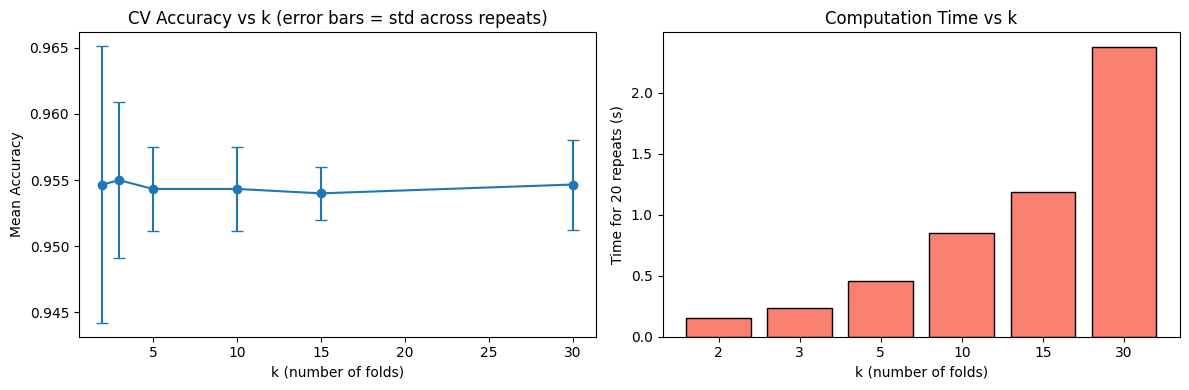

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].errorbar(k_df['k'],k_df['Mean Accuracy'],yerr=k_df['Std across repeats'],marker='o',capsize=4)
axes[0].set_xlabel('k (number of folds)')
axes[0].set_ylabel('Mean Accuracy')
axes[0].set_title('CV Accuracy vs k (error bars = std across repeats)')

axes[1].bar(k_df['k'].astype(str),k_df['Time (s)'],color='salmon',edgecolor='k')
axes[1].set_xlabel('k (number of folds)')
axes[1].set_ylabel('Time for 20 repeats (s)')
axes[1].set_title('Computation Time vs k')
plt.tight_layout()
plt.show()

## Comparison of Bootstrapping and Cross-Validation

In [11]:
summary=pd.DataFrame({
    'Method':['Single hold-out (10 seeds)','Bootstrap (1000, OOB)','5-fold CV','10-fold CV'],
    'Accuracy (mean)':[np.mean(holdout_acc),np.mean(boot_acc),cv_results[5]['acc'].mean(),cv_results[10]['acc'].mean()],
    'F1 macro (mean)':[np.nan,np.mean(boot_f1),cv_results[5]['f1'].mean(),cv_results[10]['f1'].mean()],
    'Accuracy (std)':[np.std(holdout_acc),np.std(boot_acc),cv_results[5]['acc'].std(),cv_results[10]['acc'].std()],
    'Models trained':[10,len(boot_acc),5,10],
    'Time (s)':[np.nan,boot_time,cv_results[5]['time'],cv_results[10]['time']]
})
summary

,Method,Accuracy (mean),F1 macro (mean),Accuracy (std),Models trained,Time (s)
0,Single hold-out (10 seeds),0.956667,NaN,0.036667,10,NaN
1,"Bootstrap (1000, OOB)",0.956775,0.956029,0.024095,1000,4.796157
2,5-fold CV,0.953333,0.953216,0.045216,5,0.029578
3,10-fold CV,0.953333,0.952576,0.052068,10,0.054871


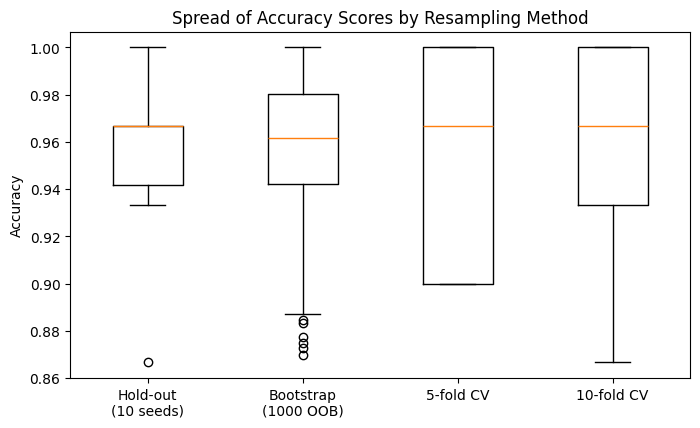

In [12]:
plt.figure(figsize=(8,4.5))
data=[holdout_acc,boot_acc,cv_results[5]['acc'],cv_results[10]['acc']]
plt.boxplot(data,labels=['Hold-out\n(10 seeds)','Bootstrap\n(1000 OOB)','5-fold CV','10-fold CV'])
plt.ylabel('Accuracy')
plt.title('Spread of Accuracy Scores by Resampling Method')
plt.show()

## Discussion — Advantages and Disadvantages
**What the numbers show.** A single hold-out split is unreliable: across ten random seeds its accuracy ranged from 0.867 to 1.000 (std 0.037), so the figure you report depends on luck. Both resampling methods agree closely with each other and give a much more trustworthy picture: bootstrapping (1000 iterations, out-of-bag evaluation) gave accuracy 0.957 and macro F1 0.956, while 5-fold and 10-fold CV both gave accuracy 0.953 and F1 about 0.953. The gap between methods (about 0.4 percentage points) is far smaller than the spread of any single estimate, so on this dataset they tell the same story.

A caution when comparing the standard deviations: the bootstrap std (0.024) measures variation across 1000 OOB test sets of roughly 55 samples each, whereas the CV std (0.045 for 5-fold, 0.052 for 10-fold) measures variation across individual folds of only 30 or 15 samples. Smaller test sets give noisier scores, which is why the 10-fold per-fold std is larger even though its *average* is just as good. These numbers are not directly comparable as 'which method is more stable'.

**Choice of k.** In the repeated-CV sweep the mean accuracy was essentially flat (0.954 to 0.955) for every k from 2 to 30, but the run-to-run variability of the estimate fell from 0.0105 at k=2 to about 0.003 at k=5 and k=10 and 0.002 at k=15, while computation grew in direct proportion to the number of models trained (0.16 s for 40 models versus 2.4 s for 600). Moderate values such as 5 or 10 give most of the stability at a small fraction of the cost.

### Bootstrapping
**Advantages**
- Produces a full *distribution* of scores, so you can report a standard deviation and a confidence interval (here accuracy 0.91 to 1.00), not just a single mean.
- Works with very small datasets and can be repeated as many times as you like; the number of iterations is independent of the dataset size.
- Each iteration has a large training set (the same size as the original data), and the OOB rows give a free test set.
- The same idea underlies Bagging and Random Forests.

**Disadvantages**
- Computationally heavier: 1000 models took about 4.8 s versus 0.05 s for 10-fold CV.
- A bootstrap sample contains only about 63% of the unique rows, so each model sees less distinct information than the full data, which can bias the OOB estimate (typically pessimistic; the .632 and .632+ corrections exist for this reason). The bias was not visible on Iris, but it is a known property.
- Duplicated rows inside a training sample and a variable OOB size make individual iterations less clean (a few iterations can even have very few OOB rows).
- Samples are drawn independently, so it does not guarantee class balance in the OOB set unless stratified.

### k-Fold Cross-Validation
**Advantages**
- Every sample is used for testing exactly once and for training k-1 times, so all data is used efficiently.
- Cheap and deterministic in cost: only k models; very fast here.
- Stratification keeps class proportions the same in every fold.
- Lower-bias estimate than a single hold-out, and the standard method for model selection and tuning.

**Disadvantages**
- Gives only k scores, so the spread and any interval are rough, and the folds are not independent because their training sets overlap heavily.
- Each model is trained on only (k-1)/k of the data, so small k (e.g. 2 or 3) is pessimistic and noisy, while large k costs more and gives very small test folds.
- The result depends on how the data was shuffled into folds; repeated CV is needed to see this variation.
- Needs care with time series or grouped data, where random folds leak information.

**Rule of thumb:** use stratified k-fold (k = 5 or 10) as the default for model evaluation and tuning; use bootstrapping when you want an uncertainty estimate (confidence interval) for a metric, or when the dataset is very small.

## Conclusion
Logistic Regression (with scaling inside a pipeline to avoid leakage) was evaluated on Iris using a single hold-out split, 1000-iteration bootstrapping with out-of-bag testing, and 5- and 10-fold stratified cross-validation. A single split proved unreliable (accuracy 0.867 to 1.000 depending on the seed), whereas bootstrapping (accuracy 0.957, F1 0.956) and cross-validation (accuracy 0.953, F1 0.953) agreed closely. Bootstrapping is better for quantifying uncertainty through a score distribution and confidence interval, at higher computational cost; k-fold cross-validation uses every sample for testing exactly once, is far cheaper, and is the standard choice for routine model evaluation, with k = 5 or 10 offering a good balance of stability and cost.